In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, ConcatDataset
from torchvision.utils import draw_bounding_boxes
from torchvision import transforms
import matplotlib.pyplot as plt
from math import ceil, floor
from datetime import datetime 
from scipy.special import expit
torch.manual_seed(123)

### Preprocessing dataset (3.1.1)

In [3]:
def convert_for_detection(dataset, H_out, W_out):
    
    converted_dataset = torch.zeros(len(dataset), H_out, W_out, 6)
    for i, obs in enumerate(dataset):
        for image in obs:
            pc, x, y, w, h, c = image
            col = int((x * W_out))
            row = int((y * H_out))

            x_local = W_out * x - col 
            y_local = H_out * y - row 
            w_local = w * W_out 
            h_local = h * H_out 

            converted_dataset[i][row][col] = torch.tensor([pc, x_local, y_local, w_local, h_local, c])
    return converted_dataset

# Detection

In [ ]:
device = (torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu'))
print(f"Training on device {device}.")

class DetectionNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=(6,5))
        self.conv4 = nn.Conv2d(64, 7, 1)
        
    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = self.conv4(x)
        x = x.permute(0,2, 3, 1)
        return x

class DetectionNetModular(nn.Module):
    def __init__(self, conv_channels=[16, 32, 64]):
        super().__init__()
        layers = []
        channels = [1] + conv_channels

        h, w = (48, 60)
        for i in range(len(conv_channels) - 1):
            h, w = h // 2, w // 2
        final_kernel_size = (h // 2, w // 3)


        for i in range(len(conv_channels)):
            layers.append(nn.Conv2d(channels[i], channels[i+1], 3, padding=1))
            layers.append(nn.ReLU())
            if i < (len(conv_channels) - 1):
                layers.append(nn.MaxPool2d(2, 2))
            else:
                layers.append(nn.MaxPool2d(kernel_size=final_kernel_size))

        self.hidden = nn.Sequential(*layers)
        self.final = nn.Conv2d(conv_channels[-1], 7, 1)
    
    def forward(self, x):
        x = self.hidden(x)
        x = self.final(x)
        x = x.permute(0,2,3,1)
        return x
    
def detection_loss(y_pred, y_true):
    detection_c = nn.BCEWithLogitsLoss()
    localization_c = nn.MSELoss(reduction='none')  # 'none' to mask by cell
    classification_c = nn.CrossEntropyLoss(reduction='none')

    # Detection for all cells
    det_loss = detection_c(y_pred[:, 0], y_true[:, 0])

    # 1.0 where object exists, 0.0 when not, multiply by loss to only apply loss to detected obj
    obj_mask = y_true[:, 0]  

    loc_loss = localization_c(y_pred[:, 1:5], y_true[:, 1:5]) 
    loc_loss = (loc_loss.mean(dim=1) * obj_mask).mean()

    cls_pred = y_pred[:, 5:]       
    cls_target = y_true[:, -1].long()
    cls_loss = classification_c(cls_pred, cls_target)  
    cls_loss = (cls_loss * obj_mask).mean()

    return det_loss + loc_loss + cls_loss
        
        

Training on device cuda.


### Load data and preprocessing

In [5]:
def visualize_samples_detection(dataset, num_samples=8, Hout=2, Wout=3, img_w=60, img_h=48):
    fig, axes = plt.subplots(1, num_samples, figsize=(20, 3))

    for i in range(num_samples):
        img, label = dataset[i]  # label shape: (Hout, Wout, 6)
        img = img.cpu()
        label = label.cpu()
        img = img.squeeze(0)
        img = img.repeat(3, 1, 1)
        img = (img * 255).byte()

        boxes = []
        for row in range(Hout):
            for col in range(Wout):
                cell = label[row, col]
                if cell[0].item() == 1:  
                    x_l, y_l, w_l, h_l = cell[1:5]

                    # Convert local cell coords to global image coords
                    x_g = (col + x_l) / Wout
                    y_g = (row + y_l) / Hout
                    w_g = w_l / Wout
                    h_g = h_l / Hout

                    x1 = (x_g - w_g / 2) * img_w
                    y1 = (y_g - h_g / 2) * img_h
                    x2 = (x_g + w_g / 2) * img_w
                    y2 = (y_g + h_g / 2) * img_h
                    
                    # Sometimes in training, the net would make impossible predictions which resulted in errors in vis function
                    if x2 > x1 and y2 > y1:
                        boxes.append([x1, y1, x2, y2])
                        
        if boxes:
            boxes_t = torch.tensor(boxes).float()
            img = draw_bounding_boxes(img, boxes_t, colors=(255, 255, 0), width=2)

        axes[i].imshow(img.permute(1, 2, 0))
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

In [6]:
detection_test = torch.load("data/detection_test.pt")
detection_train = torch.load("data/detection_train.pt")
detection_val = torch.load("data/detection_val.pt")
list_y_true_test = torch.load("data/list_y_true_test.pt")
list_y_true_val = torch.load("data/list_y_true_val.pt")
y_test = convert_for_detection(list_y_true_test, 2, 3)
y_val = convert_for_detection(list_y_true_val, 2, 3)


C:\Users\eirik\AppData\Local\Temp\ipykernel_22296\2385814367.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  detection_test = torch.load("data/detection_test.pt")
C:\Use

In [ ]:
print(y_test[:5])
print(detection_test.tensors[1][:5])

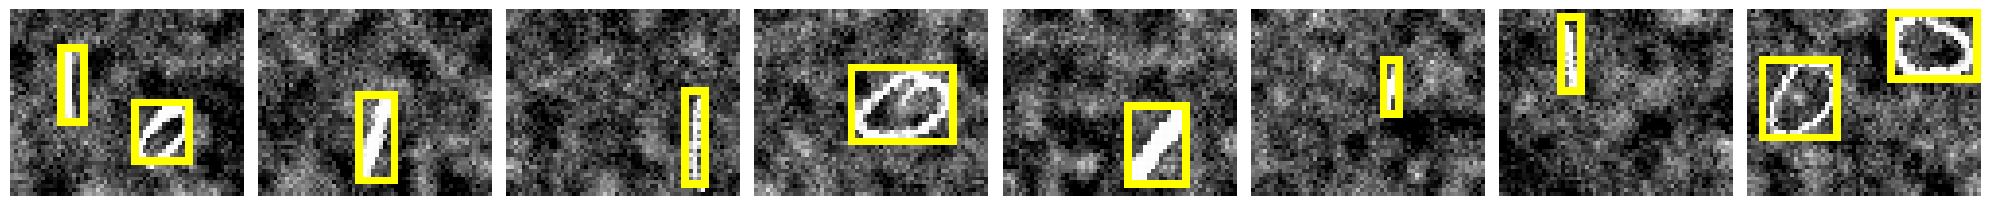

In [7]:
visualize_samples_detection(detection_train)

### Normalize Images

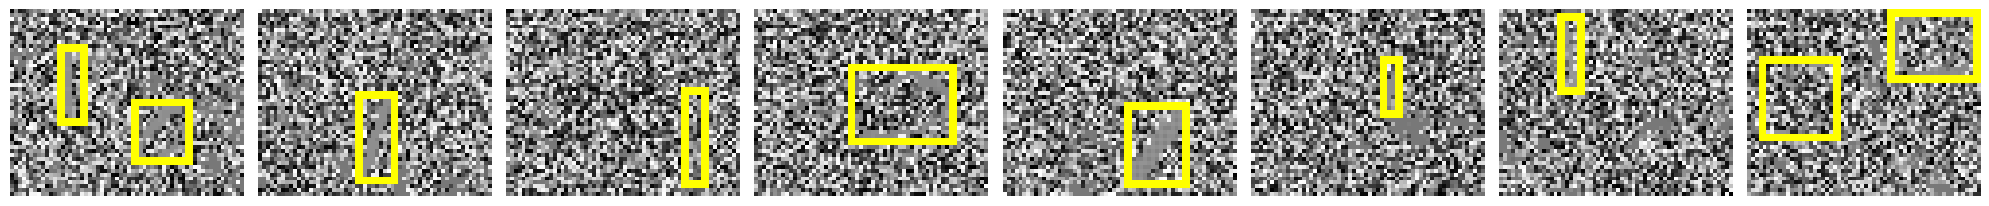

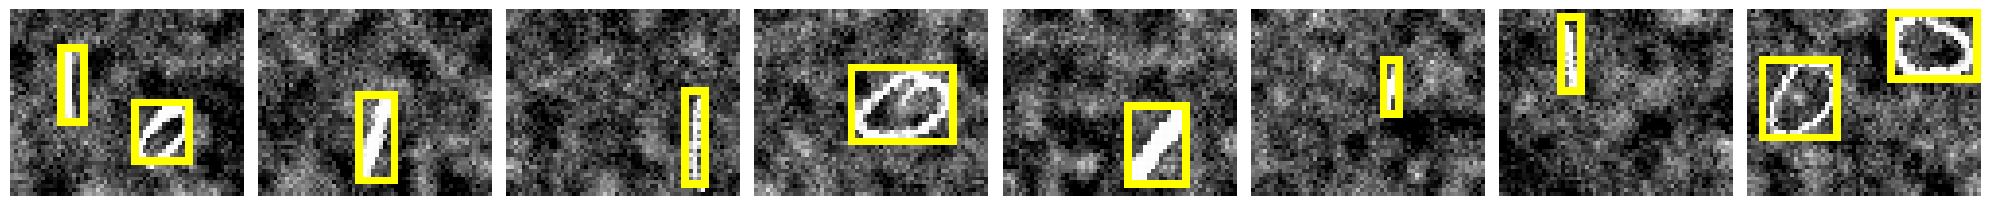

In [8]:
def normalize(dataset):
    #Compute mean/standard deviation
    loader = DataLoader(dataset)
    mean = 0
    std = 0
    total = 0
    for img, _ in loader:
        batch_size = img.size(0)
        img = img.view(batch_size, img.size(1), img.size(2)*img.size(3))  # flatten pixels to 1 dim for mean/std
        mean += img.mean(2).sum(0)
        std += img.std(2).sum(0)
        total += batch_size

    mean /= total
    std /= total
    
    # Perform normalization
    normalize_fn = transforms.Normalize(mean=mean, std=std)
    normalized_tensors = normalize_fn(dataset.tensors[0])  
    labels = dataset.tensors[1]                           

    return TensorDataset(normalized_tensors, labels)

det_train_normalized = normalize(detection_train)

visualize_samples_detection(det_train_normalized)
visualize_samples_detection(detection_train)

### Model selection and evaluation

In [9]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision



def get_map_results(model, eval_loader, device):
    '''
        Helper functions to get predictions and targets in the format required for mAP calculation.
        Depending on your data processing and model architecture this function can either be used as is, 
        modified to fit your needs or used as a blue print for a rewrite.
        Here it is assussmed that the image has been divide into a 2 x 3 grid.
        ----------------------------------------------------------
        Run through the data in the dataloader and collect predicitions and targets for mAP calculation.

        torchmetric mAP expects predictions and targets in the format:
        preds = [
           { "boxes": tensor([[x1, y1, x2, y2], ...]), "scores": tensor([score1, score2, ...]), "labels": tensor([label1, label2, ...])},
            ...   ]
        and targets = [
            { "boxes": tensor([[x1, y1, x2, y2], ...]), "labels": tensor([label1, label2, ...])},
            ...   ]
        where each dict in the list corresponds to one image in the dataset and contains the predicted and true results
    '''
    model.eval()
    with torch.no_grad():
        preds = []
        targets = []
        for images, labels in eval_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            #outputs = outputs.permute(0, 2, 3, 1)                               # (B, 7, 2, 3) → (B, 2, 3, 7)
            outputs = outputs.reshape(outputs.shape[0], -1, outputs.shape[-1])  # (B, 2, 3, 7) → (B, 6, 7)
            labels = labels.reshape(labels.shape[0], -1, labels.shape[-1])      # (B, 2, 3, 6) → (B, 6, 6)
            for output, label in zip(outputs, labels):
                pred_boxes = []
                pred_scores = []
                pred_labels = []
                target_boxes = []
                target_labels = []
                # collect predicted boxes, scores and labels for the current image
                for i, cell_output in enumerate(output):
                    pred_object_presence = (torch.sigmoid(cell_output[0]) > 0.5) * 1.0
                    if pred_object_presence == 1:
                        # get propability of object presence and class probabilities to compute detection score for mAP calculation
                        obj_prop = torch.sigmoid(cell_output[0]).item()
                        class_prop = F.softmax(cell_output[5:], dim=0)
                        pred_label = torch.argmax(class_prop)
                        detect_score = obj_prop * class_prop[pred_label]
                        # convert from local to global coordinates before we can compare with the labels and compute IoU for mAP calculation
                        bbox_global = local_to_global(i // 3, i % 3, cell_output[1:5])
                        bbox_xyxy = xywh_to_xyxy(bbox_global)
                        bbox_xyxy = torch.stack(bbox_xyxy)
                        # collect predicted boxes, scores and labels for the current image
                        pred_boxes.append(bbox_xyxy)
                        pred_scores.append(detect_score)
                        pred_labels.append(pred_label.item())
                        
                # collect true boxes and labels for the current image
                for i, cell_label in enumerate(label):
                    true_object_presence = cell_label[0]
                    if true_object_presence == 1:
                        bbox_global = local_to_global(i // 3, i % 3, cell_label[1:5])
                        bbox_xyxy = xywh_to_xyxy(bbox_global)
                        bbox_xyxy = torch.stack(bbox_xyxy)
                        target_boxes.append(bbox_xyxy)
                        target_labels.append(int(cell_label[-1]))
                
                # store predictions and targets for the current image in the format required for mAP calculation
                # if there are no predicted boxes, we need to create an empty tensor for the boxes, scores and labels to avoid errors in the mAP calculation
                if len(pred_boxes) == 0:
                    pred_dict = {
                        "boxes": torch.zeros((0, 4), device=device),
                        "scores": torch.zeros((0,), device=device),
                        "labels": torch.zeros((0,), dtype=torch.long, device=device),
                    }
                    preds.append(pred_dict)
                else:
                    pred_dict = {
                        "boxes": torch.stack(pred_boxes),
                        "scores": torch.tensor(pred_scores, device=device),
                        "labels": torch.tensor(pred_labels, device=device),
                    }
                    preds.append(pred_dict)
                # if there are no true boxes, we need to create an empty tensor for the boxes and labels to avoid errors in the mAP calculation            
                if len(target_boxes) == 0:
                    target_dict = {
                        "boxes": torch.zeros((0, 4), device=device),
                        "labels": torch.zeros((0,), dtype=torch.long, device=device),
                    }
                    targets.append(target_dict)
                else:
                    target_dict = {
                        "boxes": torch.stack(target_boxes),
                        "labels": torch.tensor(target_labels, device=device),
                    }
                    targets.append(target_dict)
    
    # compute mAP using torchmetrics
    metric = MeanAveragePrecision(iou_type="bbox")
    metric.update(preds, targets)
    results = metric.compute()
    # results is a dict with the mAP results for different IoU thresholds and the overall mAP

    detection, classification = get_accuracies(preds, targets)
    
    return results, detection, classification   

def local_to_global(i, j, bb, width=60, height=48, cols=3, rows=2):
    x, y, w, h = bb
    # get the dimensions of a single grid cell
    cell_width, cell_height = width / cols, height / rows
    # convert from local to global coordinates
    global_x = x * cell_width + j * cell_width
    global_y = y * cell_height + i * cell_height
    global_w = w * cell_width
    global_h = h * cell_height

    return global_x, global_y, global_w, global_h

def xywh_to_xyxy(bb):
    # convert from center format to box format
    x_center, y_center, w, h = bb
    x1 = x_center - w/2
    y1 = y_center - h/2
    x2 = x_center + w/2
    y2 = y_center + h/2
    return x1, y1, x2, y2   

def get_accuracies(preds, targets):
    total = len(preds)

    correct = 0
    for pred, target in zip(preds, targets):
        pred_exist = len(pred['boxes']) > 0
        true_exist = len(target['boxes']) > 0
        if pred_exist == true_exist:
            correct += 1
    detection_accuracy = correct / total 

    correct_class = 0
    class_total = 0
    for pred, target in zip(preds, targets):
        if len(pred['labels']) > 0 and len(target['labels']) > 0:
            class_total += 1
            if pred['labels'][0].item() == target['labels'][0].item():
                correct_class += 1
    classification_accuracy = correct_class / class_total if class_total else 0 

    return detection_accuracy, classification_accuracy
    

## Train Loop:

In [ ]:
def train_loop(dataset, val_loader, net, n_epochs, batch_size=32, criterion=detection_loss, lr=0.001, momentum=0.9, visualize=False):
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)
    train_loader = DataLoader(dataset, batch_size=batch_size)

    all_images = dataset.tensors[0]

    history = {
        'train_loss': [],
        'val_loss': [],
        'val_map_50': [],
        'val_detection_accuracy': [],
    }

    for epoch in range(n_epochs):
        # Training
        net.train()
        epoch_loss = 0.0

        for i, (images, labels) in enumerate(train_loader):
            optimizer.zero_grad()

            images = images.to(device)
            labels = labels.to(device)
            outputs = net(images)

            B, R, C, D = outputs.shape
            loss = criterion(
                outputs.reshape(B * R * C, D),
                labels.reshape(B * R * C, labels.shape[-1]) )
            epoch_loss += loss.item()

            loss.backward()
            optimizer.step()

        history['train_loss'].append(epoch_loss / len(train_loader))

        # Validation
        val_loss = 0.0
        net.eval()
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = net(images)
                B, R, C, D = outputs.shape
                loss = criterion(
                    outputs.reshape(B * R * C, D),
                    labels.reshape(B * R * C, labels.shape[-1])
                )
                val_loss += loss.item()
        history['val_loss'].append(val_loss / len(val_loader))

        # Since MAP is a lot, only request every 5 epochs
        if (epoch + 1) % 5 == 0 or epoch == n_epochs - 1:
            results = get_map_results(net, val_loader, device)
            history['val_map_50'].append((epoch, results[0]['map_50'].item()))
            history['val_detection_accuracy'].append((epoch, results[1]))

        if visualize:
            print(f'Predictions epoch {epoch}:')
            net.eval()
            predicted_labels = []

            with torch.no_grad():
                for  images, _ in train_loader:
                    images = images.to(device)
                    outputs = net(images)

                    for batch in range(outputs.shape[0]):
                        cell_preds = []

                        for row in range(outputs.shape[1]):
                            for col in range(outputs.shape[2]):
                                cell = outputs[batch, row, col]

                                pred_detection = torch.sigmoid(cell[0]).round().unsqueeze(0)
                                pred_class = torch.argmax(cell[5:]).unsqueeze(0).float()
                                pred = torch.cat([pred_detection, cell[1:5].detach(), pred_class])
                                cell_preds.append(pred)

                        predicted_labels.append(torch.stack(cell_preds).view(2, 3, 6).cpu())
            
            visualize_samples_detection(TensorDataset(all_images, torch.stack(predicted_labels)))
            visualize_samples_detection(dataset)
    return net, history


Predictions epoch 0:


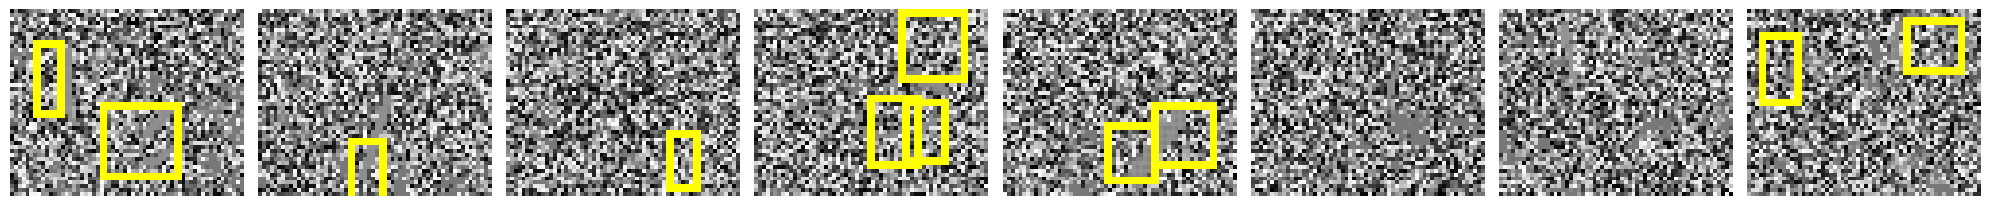

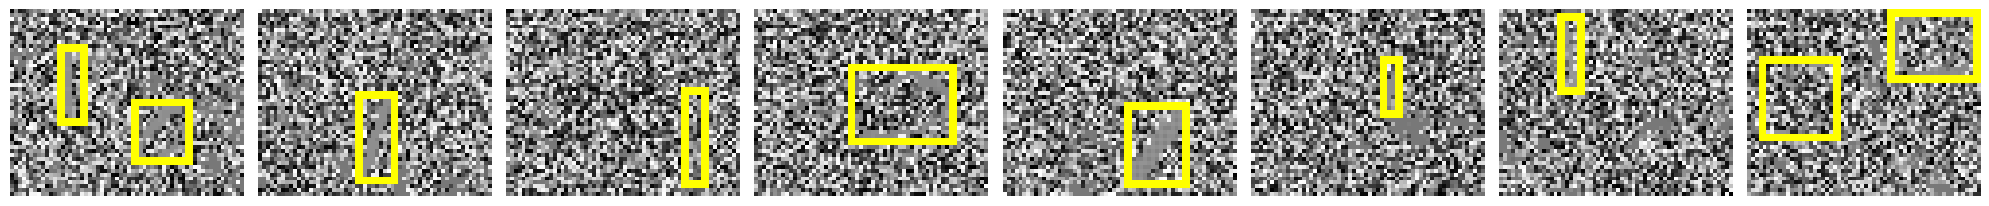

Predictions epoch 1:


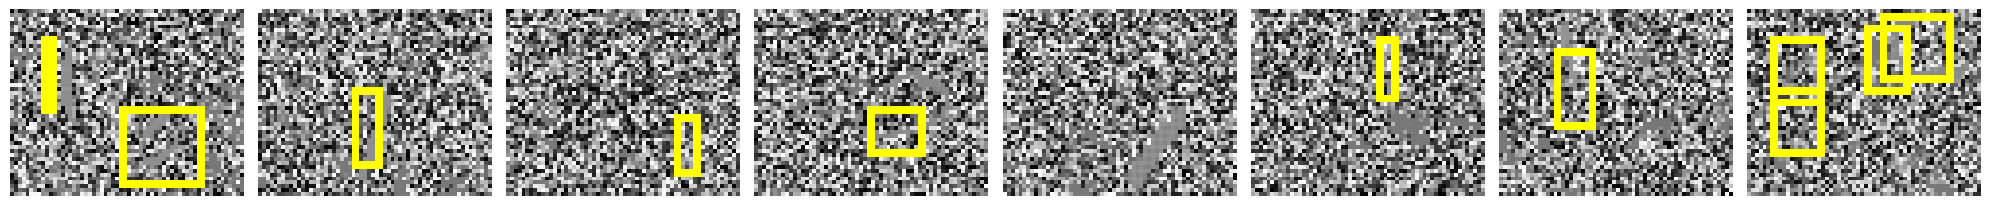

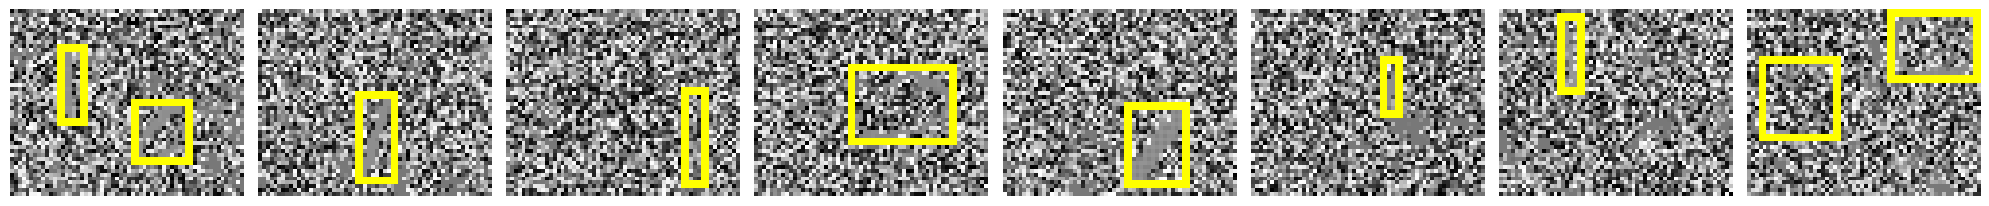

Predictions epoch 2:


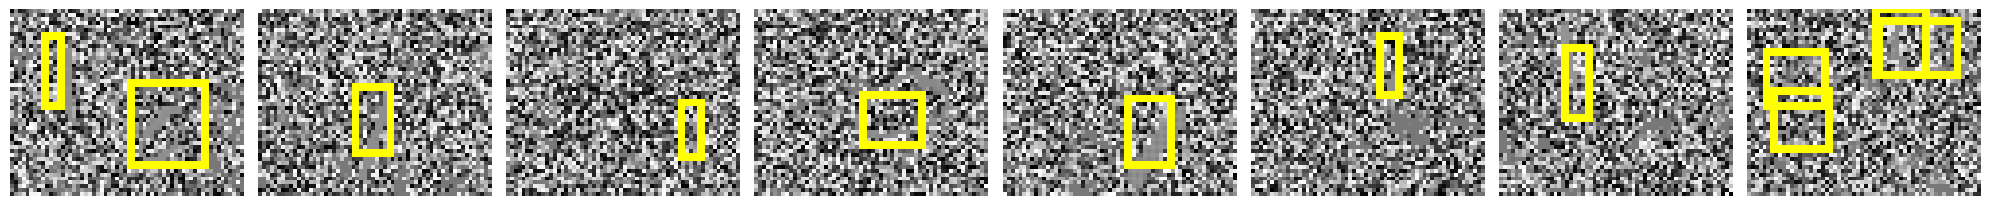

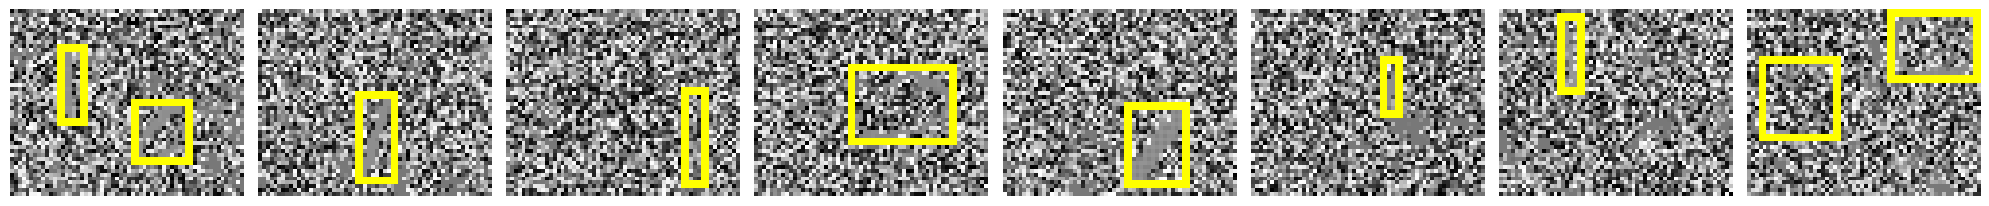

In [11]:
det_val_norm = normalize(detection_val)
val_loader = DataLoader(det_val_norm)

train_loader = DataLoader(det_train_normalized)
net = DetectionNetModular().to(device)
net, history = train_loop(det_train_normalized, val_loader, net, 3, visualize=True)



## Model Selection:

In [33]:
import itertools
import random


def select_best_model(hyperparameter_grid, dataset, eval_loader, device, n_models):
    seed = 7007
    random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    best_score = 0
    best_parameters = None
    best_model = None
    best_results = None

    all_results = []

    for i in range(n_models):
        parameters = random.choice(hyperparameter_grid)
        print("Training model using parameters: ", parameters)
        lr, bs, momentum, epochs, architecture = parameters
        net = DetectionNetModular(architecture).to(device)
        _, histories = train_loop(dataset=dataset, val_loader=eval_loader, net=net, n_epochs=epochs, batch_size=bs, lr=lr, momentum=momentum)
        results = get_map_results(model=net, eval_loader=eval_loader, device=device)

        all_results.append([results, histories, parameters])

        if results[0]['map_50'].item() > best_score:
            best_score = results[0]['map_50'].item()
            best_results = results
            best_parameters = parameters
            best_model = net
        
    return best_model, best_parameters, best_results, all_results

det_val_norm = normalize(detection_val)
val_loader = DataLoader(det_val_norm)

learning_rates = [0.001, 0.005, 0.01, 0.05]
batch_sizes = [8, 16, 32, 64]
momentums = [1, 0.95, 0.9, 0.8, 0.6]
n_epochs = [10, 20, 30]
architectures = [[16, 32], [32, 64], [16, 32, 64], [32, 64, 128], [16, 32, 64, 128]]

grid = list(itertools.product(learning_rates, batch_sizes, momentums, n_epochs, architectures))

best_model, best_parameters, best_score, results = select_best_model(grid, det_train_normalized, val_loader, device, 10)
lr, bs, momentum, epochs, architecture = best_parameters

print(f'''Best parameters found were:
        Learning rate: {lr}
        Batch size: {bs}
        Momentum: {momentum}
        Training epochs: {epochs}
        Architecture: {architecture}

        mAP:''')
print(best_score)


Training model using parameters:  (0.05, 32, 0.9, 20, [16, 32, 64, 128])
Training model using parameters:  (0.01, 32, 1, 20, [16, 32, 64, 128])
Training model using parameters:  (0.005, 64, 0.95, 10, [32, 64])
Training model using parameters:  (0.05, 32, 0.9, 30, [32, 64, 128])
Training model using parameters:  (0.001, 32, 1, 30, [32, 64, 128])
Training model using parameters:  (0.01, 16, 0.9, 30, [16, 32, 64, 128])
Training model using parameters:  (0.005, 8, 1, 30, [16, 32])
Training model using parameters:  (0.05, 16, 0.9, 10, [16, 32, 64, 128])
Training model using parameters:  (0.01, 64, 0.9, 20, [16, 32, 64, 128])
Training model using parameters:  (0.05, 16, 0.95, 30, [16, 32, 64])
Best parameters found were:
        Learning rate: 0.01
        Batch size: 64
        Momentum: 0.9
        Training epochs: 20
        Architecture: [16, 32, 64, 128]

        mAP:
({'map': tensor(0.3605), 'map_50': tensor(0.8409), 'map_75': tensor(0.2272), 'map_small': tensor(0.3605), 'map_medium': 

## Training a model with the best parameters:

In [37]:
lr, bs, momentum, epochs, architecture = best_parameters

images = torch.cat([det_train_normalized.tensors[0], det_val_norm.tensors[0]])
labels = torch.cat([det_train_normalized.tensors[1], det_val_norm.tensors[1]])
combined_data = TensorDataset(images, labels)
testloader = DataLoader(normalize(detection_test), batch_size=16)

net, history = train_loop(combined_data, testloader, best_model, 10, bs, criterion=detection_loss, lr=lr/10, momentum=momentum)


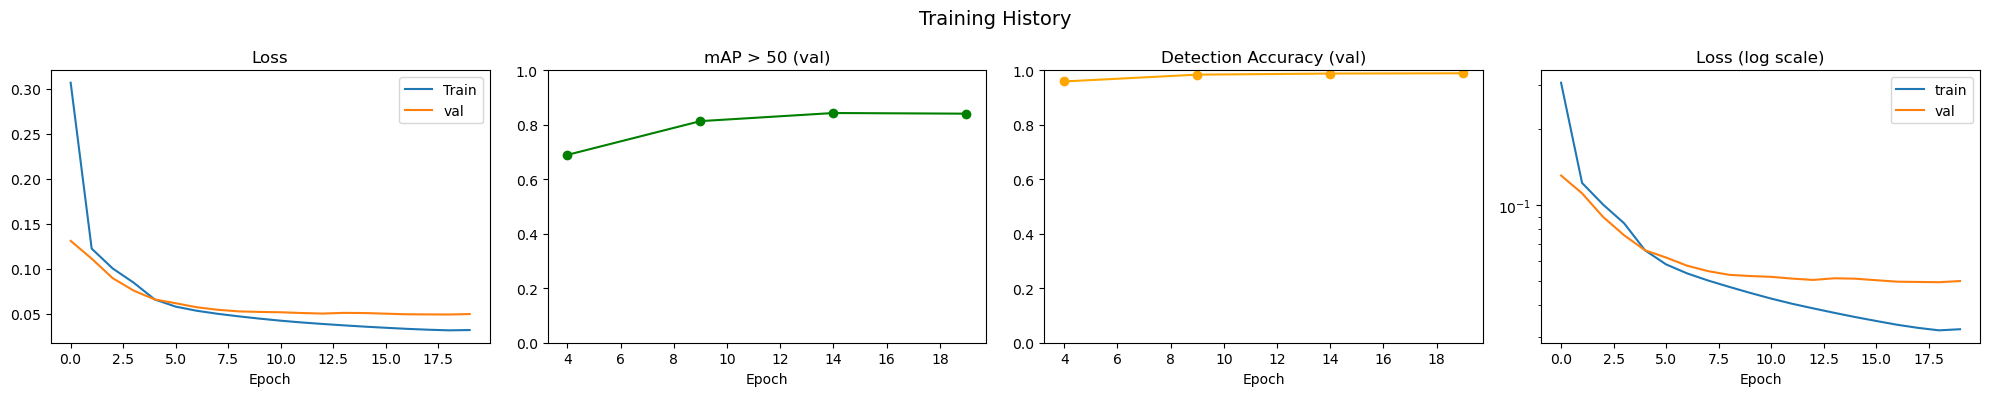

In [39]:
def plot_history(history):
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    axes[0].plot(history['train_loss'], label='Train')
    axes[0].plot(history['val_loss'], label='val')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    epochs, scores = zip(*history['val_map_50'])
    axes[1].plot(epochs, scores, marker='o', color='green')
    axes[1].set_title('mAP > 50 (val)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylim(0, 1)

    epochs, accs = zip(*history['val_detection_accuracy'])
    axes[2].plot(epochs, accs, marker='o', color='orange')
    axes[2].set_title('Detection Accuracy (val)')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylim(0, 1)

    axes[3].plot(history['train_loss'], label='train')
    axes[3].plot(history['val_loss'], label='val')
    axes[3].set_yscale('log')
    axes[3].set_title('Loss (log scale)')
    axes[3].set_xlabel('Epoch')
    axes[3].legend()

    plt.suptitle('Training History', fontsize=14)
    plt.tight_layout()
    plt.show()

plot_history(results[8][1])



## Training final model with best parameters
(And also validation data added to training set)

In [45]:
lr, bs, momentum, epochs, architecture = best_parameters

images = torch.cat([det_train_normalized.tensors[0], det_val_norm.tensors[0]])
labels = torch.cat([det_train_normalized.tensors[1], det_val_norm.tensors[1]])
combined_data = TensorDataset(images, labels)
testloader = DataLoader(normalize(detection_test), batch_size=16)
net = DetectionNetModular(architecture).to(device)

net, history = train_loop(combined_data, testloader, net, epochs, bs, criterion=detection_loss, lr=lr, momentum=momentum)


In [46]:
results = get_map_results(net, testloader, device)

In [49]:
print(results)
print("Map_50: ", results[0]['map_50'])
print("Detection accuracy: ", results[1])
print("Classification accuracy: ", results[2])

({'map': tensor(0.3538), 'map_50': tensor(0.8247), 'map_75': tensor(0.2314), 'map_small': tensor(0.3538), 'map_medium': tensor(-1.), 'map_large': tensor(-1.), 'mar_1': tensor(0.4174), 'mar_10': tensor(0.4611), 'mar_100': tensor(0.4611), 'mar_small': tensor(0.4611), 'mar_medium': tensor(-1.), 'mar_large': tensor(-1.), 'map_per_class': tensor(-1.), 'mar_100_per_class': tensor(-1.), 'classes': tensor([0, 1], dtype=torch.int32)}, 0.9702870909455933, 0.9894475481067659)
Map_50:  tensor(0.8247)
Detection accuracy:  0.9702870909455933
Classification accuracy:  0.9894475481067659
